<a href="https://colab.research.google.com/github/leozeze/LRP1_heart/blob/main/02_notebooks/03_fibroblast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03. 섬유모세포의 LRP1, sheddase 발현

README의 **분석 2, 3, 4**에 해당합니다. 섬유모세포만 추려서 봅니다.

- 분석 2: 발현 비율과 공여자 간 일관성 (차이가 크다면 측정 조건 때문인지)
- 분석 3: 어느 섬유모세포 집단, 어느 부위에서 우세한지
- 분석 4: 어떤 sheddase가 우세한지, LRP1과 같은 세포에서 함께 검출되는지

그림과 표는 드라이브의 `05_presentation` 폴더에 `03_`으로 시작하는 이름으로 저장됩니다.

## 1. 준비

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT = Path('/content/drive/MyDrive/LRP1_heart')
SUBSET_FILE = PROJECT / '01_data' / 'subset' / 'lrp1_subset_v1.h5ad'
OUT = PROJECT / '05_presentation'
OUT.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [2]:
!pip -q install scanpy "pandas==2.2.3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import scanpy as sc
from scipy.stats import wilcoxon, spearmanr
from statsmodels.stats.multitest import multipletests

## 2. 섬유모세포만 추리기

In [3]:
ad = sc.read_h5ad(SUBSET_FILE)
fb = ad[ad.obs['cell_type'].astype(str) == 'Fibroblast'].copy()

TARGET = ['LRP1']
SHEDDASES = ['ADAM10', 'ADAM12', 'ADAM17', 'MMP14', 'MMP15', 'MMP16', 'MMP17', 'BACE1']
GENES = [g for g in TARGET + SHEDDASES if g in fb.var_names]
SHEDDASES = [g for g in SHEDDASES if g in GENES]

CHAMBER = {'LA': 'Atria', 'RA': 'Atria', 'LV': 'Ventricle', 'RV': 'Ventricle',
           'AX': 'Ventricle', 'SP': 'Ventricle', 'SAN': 'Node', 'AVN': 'Node'}
fb.obs['chamber'] = fb.obs['region'].astype(str).map(CHAMBER).fillna('Other')
fb.obs['batch'] = fb.obs['modality'].astype(str) + ' | ' + fb.obs['kit_10x'].astype(str)
for col in ['cell_state', 'region', 'donor', 'cell_or_nuclei']:
    fb.obs[col] = fb.obs[col].astype(str)

X = pd.DataFrame(fb[:, GENES].X.toarray(), columns=GENES, index=fb.obs_names)
STATES = sorted(fb.obs['cell_state'].unique())
print(f'섬유모세포 {fb.n_obs:,}개,  공여자 {fb.obs["donor"].nunique()}명')
print('세부 집단:', STATES)

섬유모세포 138,055개,  공여자 22명
세부 집단: ['FB1', 'FB2', 'FB3', 'FB4_activated', 'FB5', 'FB6', 'unclassified']


세부 집단별 세포 수와, 각 집단이 어느 부위에 분포하는지(집단 안에서의 비율, %)입니다.

In [4]:
overview = pd.crosstab(fb.obs['cell_state'], fb.obs['cell_or_nuclei'])
overview['median_counts'] = fb.obs.groupby('cell_state')['total_counts'].median().round(0)
region_pct = pd.crosstab(fb.obs['cell_state'], fb.obs['region'], normalize='index').mul(100).round(1)
overview = overview.join(region_pct.add_prefix('pct_'))
overview.to_csv(OUT / '03_overview_fb_states.csv')
overview

,Cell,Nuclei,median_counts,pct_AVN,pct_AX,pct_LA,pct_LV,pct_RA,pct_RV,pct_SAN,pct_SP
cell_state,,,,,,,,,,,
FB1,889,37820,1156.0,0.6,20.9,6.8,25.9,1.3,24.4,0.1,19.8
FB2,205,32022,2124.0,3.5,3.1,14.4,2.0,32.0,7.3,35.4,2.3
FB3,745,22159,2220.0,17.2,6.3,7.4,2.7,13.2,7.5,40.8,5.0
FB4_activated,783,26031,2017.0,27.5,7.5,5.1,19.7,2.7,7.4,19.4,10.6
FB5,468,10737,1835.0,12.3,14.8,9.2,11.9,2.3,20.4,17.8,11.4
FB6,26,4048,2800.0,7.0,9.2,3.0,15.1,2.5,19.7,26.5,16.9
unclassified,47,2075,5966.0,15.9,4.0,6.8,7.4,6.5,4.3,52.1,3.1


### 세부 집단 이름 점검

2020년 논문(Fig. 3g, 본문)의 섬유모세포 집단 표지가 이 데이터의 집단 이름과 맞는지 봅니다.
예를 들어 POSTN, TNC, FAP이 `FB4_activated`에서, OSMR, IL6ST, PTX3가 `FB3`에서 높으면 논문의 설명을 그대로 적용할 수 있습니다.

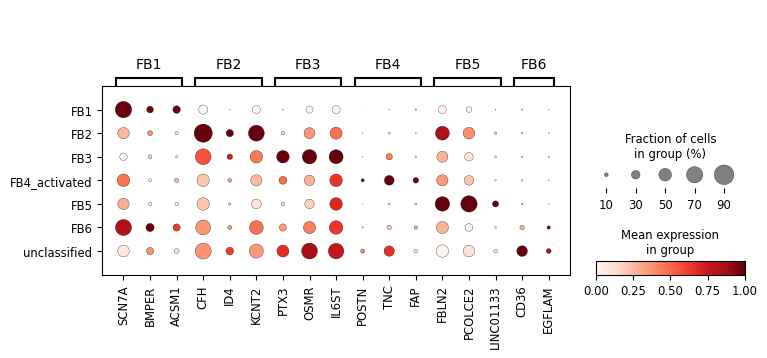

In [5]:
STATE_MARKERS = {
    'FB1': ['SCN7A', 'BMPER', 'ACSM1'], 'FB2': ['CFH', 'ID4', 'KCNT2'],
    'FB3': ['PTX3', 'OSMR', 'IL6ST'], 'FB4': ['POSTN', 'TNC', 'FAP'],
    'FB5': ['FBLN2', 'PCOLCE2', 'LINC01133'], 'FB6': ['CD36', 'EGFLAM'],
}
STATE_MARKERS = {k: [g for g in v if g in fb.var_names] for k, v in STATE_MARKERS.items()}
sc.pl.dotplot(fb, STATE_MARKERS, groupby='cell_state', standard_scale='var', show=False)
plt.savefig(OUT / '03_dotplot_fb_state_markers.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. 분석 2: 발현 비율과 공여자 간 일관성

공통으로 쓰는 계산 함수입니다. 지정한 기준(공여자, 집단 등)으로 세포를 묶어 유전자별 발현 세포 비율(pct)과 평균(mean)을 냅니다.

In [6]:
MIN_CELLS = 50      # 공여자 단위 계산에 필요한 최소 세포 수
MIN_STATE = 30      # 공여자 x 세부 집단 단위 계산에 필요한 최소 세포 수

def unit_table(cols, min_cells=MIN_CELLS, mask=None):
    obs = fb.obs if mask is None else fb.obs[mask]
    x = X if mask is None else X[mask]
    keys = [obs[col].values for col in cols]
    n = x.groupby(keys).size().rename('n_cells')
    pct = (x > 0).groupby(keys).mean().mul(100)
    mean = x.groupby(keys).mean()
    for t in (n, pct, mean):
        t.index.names = cols
    out = pct.stack().rename('pct').to_frame().join(mean.stack().rename('mean'))
    out.index.names = cols + ['gene']
    out = out.reset_index().merge(n.reset_index(), on=cols)
    return out[out['n_cells'] >= min_cells].reset_index(drop=True)

def boxes(ax, groups, values, title, highlight=None, ylabel='% cells expressing'):
    rng = np.random.default_rng(0)
    bp = ax.boxplot(values, patch_artist=True, showfliers=False, widths=0.6)
    for patch, g in zip(bp['boxes'], groups):
        patch.set_facecolor('#d9534f' if g == highlight else '#d0d0d0')
    for med in bp['medians']:
        med.set_color('black')
    for i, v in enumerate(values, start=1):
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(v)), v, s=12, color='black', alpha=0.6, zorder=3)
    ax.set_xticks(range(1, len(groups) + 1))
    ax.set_xticklabels([f'{g}\n(n={len(v)})' for g, v in zip(groups, values)], rotation=60, ha='right', fontsize=8)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.spines[['top', 'right']].set_visible(False)

is_nuc = (fb.obs['cell_or_nuclei'] == 'Nuclei').values

### 유전자별 발현 비율 (공여자당 점 하나)

섬유모세포에서 각 유전자가 검출된 세포의 비율입니다. 핵과 세포를 나눠 그립니다. LRP1은 색으로 강조했습니다.

/tmp/ipykernel_386/3760262614.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  n = x.groupby(keys).size().rename('n_cells')
/tmp/ipykernel_386/3760262614.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pct = (x > 0).groupby(keys).mean().mul(100)
/tmp/ipykernel_386/3760262614.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean = x.groupby(keys).mean()


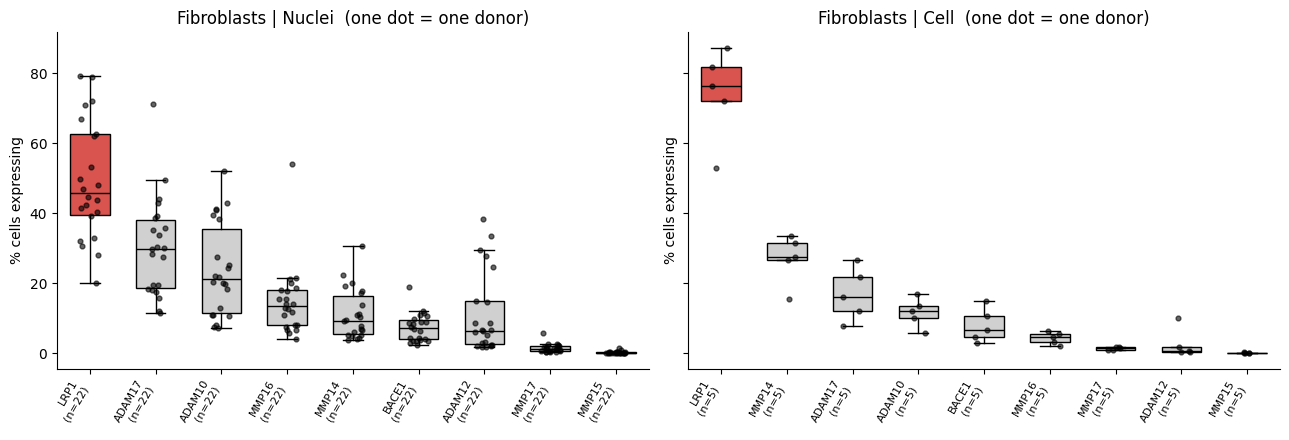

/tmp/ipykernel_386/3191159938.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  summary = by_donor.groupby(['cell_or_nuclei', 'gene'])['pct'].describe()[['count', 'min', '25%', '50%', '75%', 'max']]


count   min   25%   50%   75%   max
cell_or_nuclei gene                                       
Cell           ADAM10    5.0   5.8  10.2  12.0  13.6  17.0
               ADAM12    5.0   0.4   0.4   0.6   1.9  10.2
               ADAM17    5.0   7.9  12.0  16.0  21.7  26.7
               BACE1     5.0   3.0   4.6   6.7  10.6  14.8
               LRP1      5.0  53.0  72.2  76.5  82.0  87.4
               MMP14     5.0  15.5  26.8  27.6  31.5  33.5
               MMP15     5.0   0.0   0.1   0.2   0.2   0.4
               MMP16     5.0   2.0   3.3   4.8   5.6   6.5
               MMP17     5.0   1.0   1.1   1.5   1.7   1.9
Nuclei         ADAM10   22.0   7.3  11.5  21.1  35.6  52.1
               ADAM12   22.0   1.8   2.5   6.4  14.9  38.5
               ADAM17   22.0  11.5  18.7  29.9  38.0  71.3
               BACE1    22.0   2.4   4.0   7.3   9.6  19.0
               LRP1     22.0  20.2  39.5  45.9  62.6  79.4
               MMP14    22.0   3.7   5.5   9.4  16.4  30.5
               MMP15    22.0   0.0   0.1   0.2   0.4   1.4
               MMP16    22.0   4.0   8.1  13.5  18.0  54.2
               MMP17    22.0   0.4   0.6   1.4   1.9   5.7

In [7]:
by_donor = unit_table(['cell_or_nuclei', 'donor'])
by_donor.round(4).to_csv(OUT / '03_fb_donor_level.csv', index=False)

sources = [s for s in ['Nuclei', 'Cell'] if s in set(by_donor['cell_or_nuclei'])]
fig, axes = plt.subplots(1, len(sources), figsize=(6.5 * len(sources), 4.5), sharey=True, squeeze=False)
for ax, s in zip(axes[0], sources):
    d = by_donor[by_donor['cell_or_nuclei'] == s]
    order = d.groupby('gene')['pct'].median().sort_values(ascending=False).index
    boxes(ax, list(order), [d.loc[d['gene'] == g, 'pct'].values for g in order],
          f'Fibroblasts | {s}  (one dot = one donor)', highlight='LRP1')
plt.tight_layout()
plt.savefig(OUT / '03_fb_genes_by_donor.png', dpi=200, bbox_inches='tight')
plt.show()

summary = by_donor.groupby(['cell_or_nuclei', 'gene'])['pct'].describe()[['count', 'min', '25%', '50%', '75%', 'max']]
summary.round(1).to_csv(OUT / '03_fb_donor_summary.csv')
summary.round(1)

### 공여자 간 차이는 측정 조건 때문인가

02번 노트북에서 섬유모세포의 LRP1 비율이 공여자에 따라 20%에서 80%까지 벌어졌습니다.
이것이 사람 간의 실제 차이인지, 측정 조건의 차이인지 확인합니다.

- **batch**: 측정 방식과 시약 버전의 조합 (예: snRNA | 3prime-v2)
- **median total counts**: 세포당 잡힌 RNA 총량. 많을수록 어떤 유전자든 검출되기 쉽습니다.

점 하나는 "공여자 x batch"입니다. 왼쪽 그림에서 점들이 오른쪽 위로 올라가는 띠를 이루면, 공여자 간 차이의 상당 부분이 측정 깊이로 설명된다는 뜻입니다.

/tmp/ipykernel_386/3760262614.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  n = x.groupby(keys).size().rename('n_cells')
/tmp/ipykernel_386/3760262614.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pct = (x > 0).groupby(keys).mean().mul(100)
/tmp/ipykernel_386/3760262614.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean = x.groupby(keys).mean()
/tmp/ipykernel_386/2147255468.py:2: FutureWarning: The def

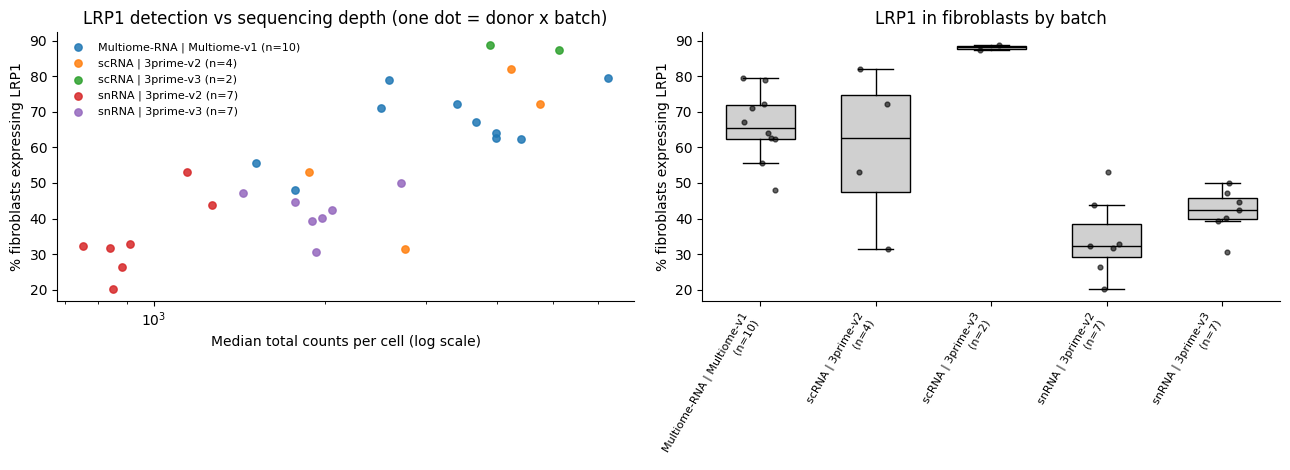

측정 깊이와 LRP1 검출 비율의 상관 (Spearman): rho = 0.76, p = 1.3e-06, 단위 수 = 30

[batch별 요약]
                                      pct  median_counts
facility batch                                          
Harvard  Multiome-RNA | Multiome-v1   NaN            NaN
         scRNA | 3prime-v2            NaN            NaN
         scRNA | 3prime-v3            NaN            NaN
         snRNA | 3prime-v2            NaN            NaN
         snRNA | 3prime-v3           41.3    1948.500000
Sanger   Multiome-RNA | Multiome-v1  65.5    3534.199951
         scRNA | 3prime-v2           62.6    3491.000000
         scRNA | 3prime-v3           88.2    4501.799805
         snRNA | 3prime-v2           32.2     882.000000
         snRNA | 3prime-v3           47.1    1432.500000


/tmp/ipykernel_386/2147255468.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(tech.groupby(['facility', 'batch'])[['pct', 'median_counts']].median().round(1))


In [8]:
units = unit_table(['donor', 'batch'])
depth = fb.obs.groupby(['donor', 'batch'])['total_counts'].median().rename('median_counts').reset_index()
fac = fb.obs.groupby(['donor', 'batch'])['facility'].first().astype(str).rename('facility').reset_index()
tech = units[units['gene'] == 'LRP1'].merge(depth, on=['donor', 'batch']).merge(fac, on=['donor', 'batch'])
tech.round(3).to_csv(OUT / '03_fb_LRP1_technical.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
batches = sorted(tech['batch'].unique())
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for i, b in enumerate(batches):
    t = tech[tech['batch'] == b]
    axes[0].scatter(t['median_counts'], t['pct'], s=28, color=colors[i % 10], label=f'{b} (n={len(t)})', alpha=0.85)
axes[0].set_xscale('log')
axes[0].set_xlabel('Median total counts per cell (log scale)')
axes[0].set_ylabel('% fibroblasts expressing LRP1')
axes[0].set_title('LRP1 detection vs sequencing depth (one dot = donor x batch)')
axes[0].legend(fontsize=8, frameon=False)
axes[0].spines[['top', 'right']].set_visible(False)
boxes(axes[1], batches, [tech.loc[tech['batch'] == b, 'pct'].values for b in batches],
      'LRP1 in fibroblasts by batch', ylabel='% fibroblasts expressing LRP1')
plt.tight_layout()
plt.savefig(OUT / '03_fb_LRP1_technical.png', dpi=200, bbox_inches='tight')
plt.show()

rho, p = spearmanr(tech['median_counts'], tech['pct'])
print(f'측정 깊이와 LRP1 검출 비율의 상관 (Spearman): rho = {rho:.2f}, p = {p:.2g}, 단위 수 = {len(tech)}')
print('\n[batch별 요약]')
print(tech.groupby(['facility', 'batch'])[['pct', 'median_counts']].median().round(1))

## 4. 분석 3: 어느 집단, 어느 부위에서 우세한가

### 세부 집단별 (전체 세포 기준)

/tmp/ipykernel_386/2771278255.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  state_pct = (X > 0).groupby(fb.obs['cell_state'].values).mean().mul(100)
/tmp/ipykernel_386/2771278255.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  state_mean = X.groupby(fb.obs['cell_state'].values).mean()


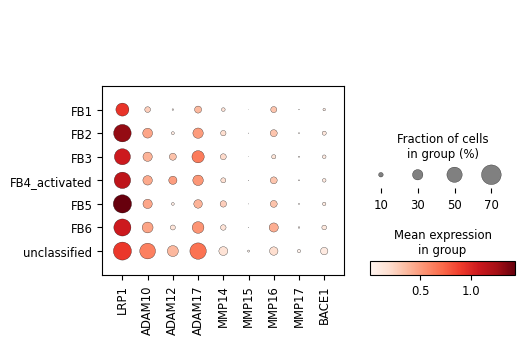

[세부 집단별 발현 세포 비율 (%)]


,LRP1,ADAM10,ADAM12,ADAM17,MMP14,MMP15,MMP16,MMP17,BACE1
FB1,40.4,13.5,2.4,17.8,7.5,0.1,14.6,0.7,4.5
FB2,60.0,27.8,5.7,29.8,12.6,0.4,17.7,1.4,8.7
FB3,53.4,25.9,17.8,37.3,14.3,0.2,9.1,1.6,7.4
FB4_activated,55.1,26.4,21.9,30.3,11.4,0.4,17.3,1.4,7.4
FB5,63.4,25.9,5.3,23.1,15.7,0.2,17.3,1.5,6.9
FB6,58.1,31.8,11.3,35.1,12.9,0.3,25.2,2.4,10.4
unclassified,62.5,52.0,32.3,54.9,24.1,3.5,22.6,6.4,19.0


In [9]:
state_pct = (X > 0).groupby(fb.obs['cell_state'].values).mean().mul(100)
state_mean = X.groupby(fb.obs['cell_state'].values).mean()
by_state = pd.concat([fb.obs['cell_state'].value_counts().rename('n_cells'),
                      state_pct.add_suffix('_pct'), state_mean.add_suffix('_mean')], axis=1)
by_state.round(3).to_csv(OUT / '03_fb_by_state.csv')

sc.pl.dotplot(fb, GENES, groupby='cell_state', cmap='Reds', show=False)
plt.savefig(OUT / '03_dotplot_fb_state.png', dpi=200, bbox_inches='tight')
plt.show()
print('[세부 집단별 발현 세포 비율 (%)]')
state_pct.round(1)

### 세부 집단별 (공여자 단위, 핵 데이터)

점 하나가 공여자 한 명입니다.

/tmp/ipykernel_386/3760262614.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  n = x.groupby(keys).size().rename('n_cells')
/tmp/ipykernel_386/3760262614.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pct = (x > 0).groupby(keys).mean().mul(100)
/tmp/ipykernel_386/3760262614.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean = x.groupby(keys).mean()
/tmp/ipykernel_386/2061700512.py:6: FutureWarning: The def

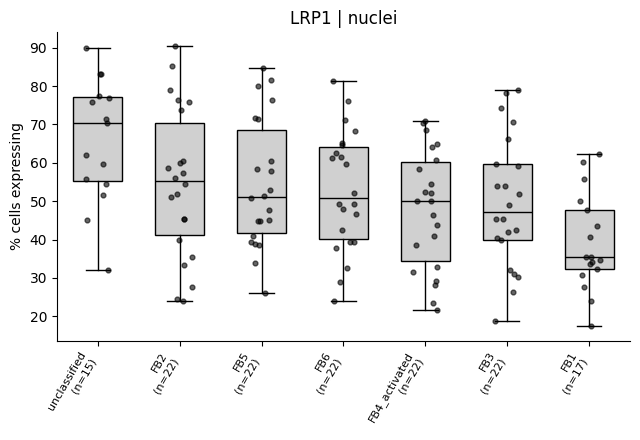

/tmp/ipykernel_386/2061700512.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = d.groupby('cell_state')['pct'].median().sort_values(ascending=False).index
/tmp/ipykernel_386/2061700512.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = d.groupby('cell_state')['pct'].median().sort_values(ascending=False).index
/tmp/ipykernel_386/2061700512.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  order = d.gr

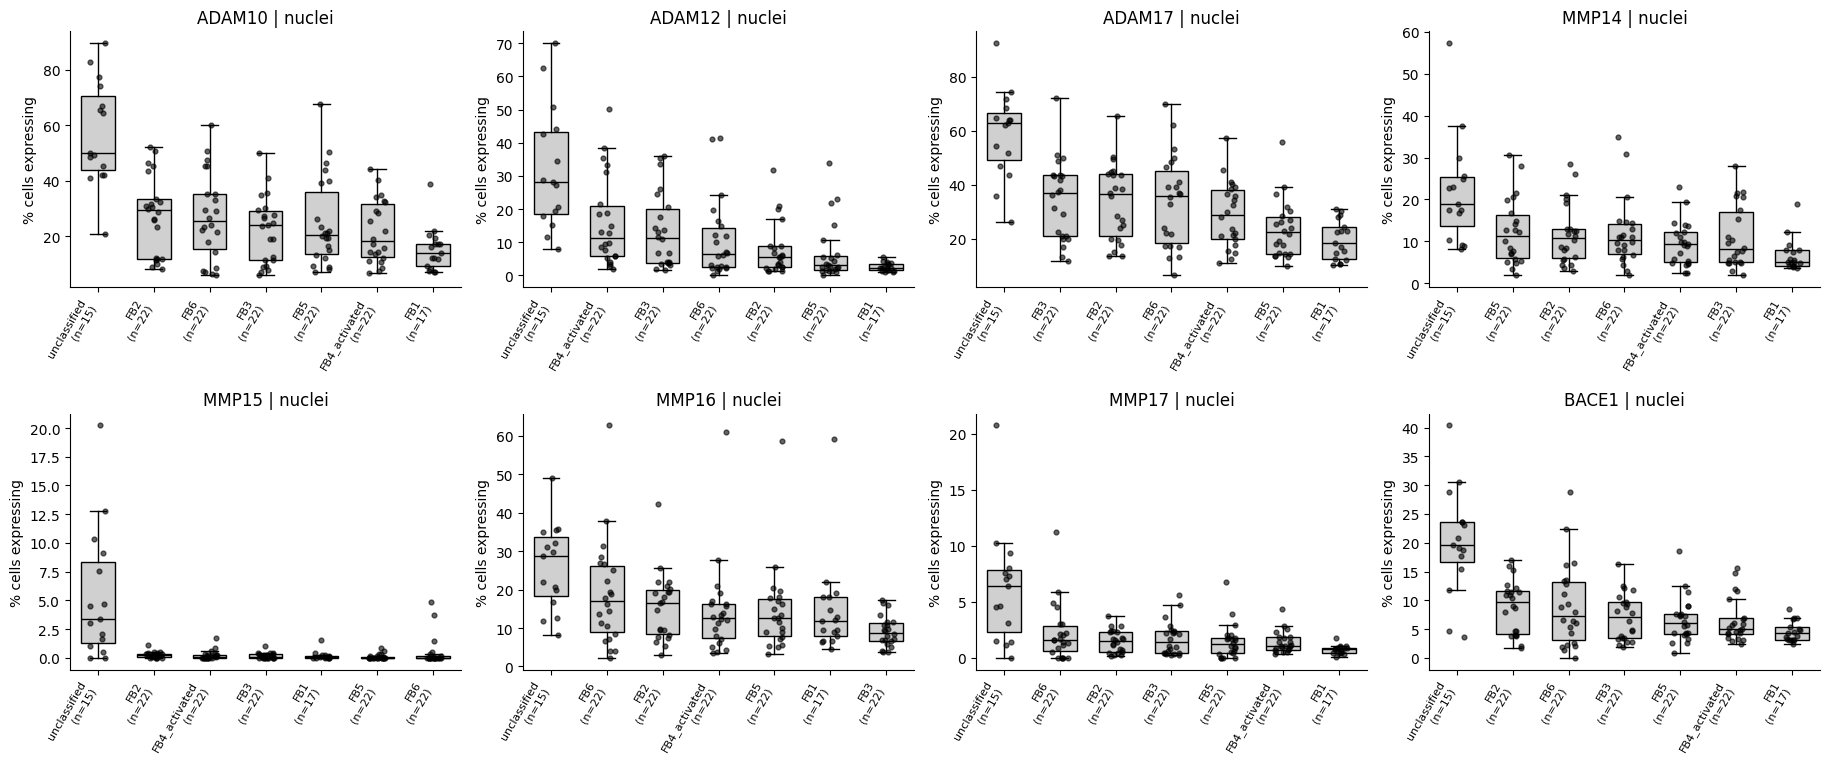

In [10]:
by_state_donor = unit_table(['donor', 'cell_state'], min_cells=MIN_STATE, mask=is_nuc)
by_state_donor.round(4).to_csv(OUT / '03_fb_state_donor_level.csv', index=False)

def state_boxplot(gene, ax):
    d = by_state_donor[by_state_donor['gene'] == gene]
    order = d.groupby('cell_state')['pct'].median().sort_values(ascending=False).index
    boxes(ax, list(order), [d.loc[d['cell_state'] == s, 'pct'].values for s in order], f'{gene} | nuclei')

fig, ax = plt.subplots(figsize=(6.5, 4.5))
state_boxplot('LRP1', ax)
plt.tight_layout()
plt.savefig(OUT / '03_fb_state_boxplot_LRP1.png', dpi=200, bbox_inches='tight')
plt.show()

ncol = 4
nrow = int(np.ceil(len(SHEDDASES) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.9 * nrow), squeeze=False)
for ax, g in zip(axes.ravel(), SHEDDASES):
    state_boxplot(g, ax)
for ax in axes.ravel()[len(SHEDDASES):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT / '03_fb_state_boxplot_sheddases.png', dpi=200, bbox_inches='tight')
plt.show()

### 각 집단 vs 나머지 섬유모세포 (통계 검정)

같은 공여자 안에서 "그 집단의 값"과 "나머지 섬유모세포의 값"을 짝지어 비교합니다(윌콕슨 부호순위 검정, 핵 데이터, Holm 보정).

- **state_higher / n_donors**: 그 집단이 더 높았던 공여자 수 / 비교한 공여자 수
- **state_median / rest_median**: 발현 세포 비율의 공여자 중앙값

In [11]:
def group_vs_rest(col, groups, min_cells=MIN_STATE):
    obs, x = fb.obs[is_nuc], (X[is_nuc] > 0)
    rows = []
    for gene in GENES:
        for g in groups:
            t = pd.DataFrame({'donor': obs['donor'].values, 'in': (obs[col] == g).values, 'pos': x[gene].values})
            agg = t.groupby(['donor', 'in'])['pos'].agg(['mean', 'size']).unstack()
            if True not in agg['size'] or False not in agg['size']:
                continue
            ok = (agg['size'][True] >= min_cells) & (agg['size'][False] >= min_cells)
            a, b = agg['mean'][True][ok] * 100, agg['mean'][False][ok] * 100
            if len(a) < 6:
                continue
            diff = a - b
            p = wilcoxon(diff).pvalue if (diff != 0).any() else 1.0
            rows.append({'gene': gene, col: g, 'n_donors': len(a), 'state_higher': int((diff > 0).sum()),
                         'state_median': a.median(), 'rest_median': b.median(), 'p': p})
    res = pd.DataFrame(rows)
    res['p_adj'] = np.nan
    for gene, ix in res.groupby('gene').groups.items():
        res.loc[ix, 'p_adj'] = multipletests(res.loc[ix, 'p'], method='holm')[1]
    return res

test_state = group_vs_rest('cell_state', STATES)
test_state.round(4).to_csv(OUT / '03_test_state_vs_rest.csv', index=False)
print('[LRP1: 각 집단 vs 나머지 섬유모세포]')
test_state[test_state['gene'] == 'LRP1'].sort_values('state_median', ascending=False).round(4)

/tmp/ipykernel_386/2220479438.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg = t.groupby(['donor', 'in'])['pos'].agg(['mean', 'size']).unstack()
/tmp/ipykernel_386/2220479438.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg = t.groupby(['donor', 'in'])['pos'].agg(['mean', 'size']).unstack()
/tmp/ipykernel_386/2220479438.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  agg = t.groupby(['donor', 'in'])['

[LRP1: 각 집단 vs 나머지 섬유모세포]


,gene,cell_state,n_donors,state_higher,state_median,rest_median,p,p_adj
6,LRP1,unclassified,15,13,70.3125,49.7119,0.0256,0.1023
1,LRP1,FB2,22,17,55.2472,46.4478,0.0007,0.0035
4,LRP1,FB5,22,18,51.1529,45.1988,0.0001,0.0008
5,LRP1,FB6,22,17,50.7195,45.7081,0.0634,0.1903
3,LRP1,FB4_activated,22,10,50.0653,44.9264,0.3209,0.6418
2,LRP1,FB3,22,7,47.1880,46.5793,0.7262,0.7262
0,LRP1,FB1,17,2,35.3673,47.2632,0.0003,0.0017


In [12]:
# 유전자 x 집단 요약: 그 집단이 나머지보다 유의하게 높으면 +, 낮으면 -, 차이 없으면 빈칸
sig = test_state.copy()
sig['mark'] = np.where(sig['p_adj'] >= 0.05, '', np.where(sig['state_median'] > sig['rest_median'], '+', '-'))
sig_table = sig.pivot(index='gene', columns='cell_state', values='mark').reindex(GENES).fillna('n/a')
sig_table.to_csv(OUT / '03_test_state_vs_rest_summary.csv')
sig_table

cell_state,FB1,FB2,FB3,FB4_activated,FB5,FB6,unclassified
gene,,,,,,,
LRP1,-,+,,,+,,
ADAM10,-,+,,,,,+
ADAM12,-,-,,+,-,,+
ADAM17,-,+,+,,-,,+
MMP14,-,,,,,,+
MMP15,,,,,-,,+
MMP16,,,-,,,+,
MMP17,-,,,,,,+
BACE1,-,+,,,,,+


### 부위별 (공여자 단위, 핵 데이터)

심방(LA, RA)과 심실(LV, RV, AX, SP)을 비교합니다. 결절 부위(SAN, AVN)는 따로 둡니다.

/tmp/ipykernel_386/3760262614.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  n = x.groupby(keys).size().rename('n_cells')
/tmp/ipykernel_386/3760262614.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pct = (x > 0).groupby(keys).mean().mul(100)
/tmp/ipykernel_386/3760262614.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean = x.groupby(keys).mean()


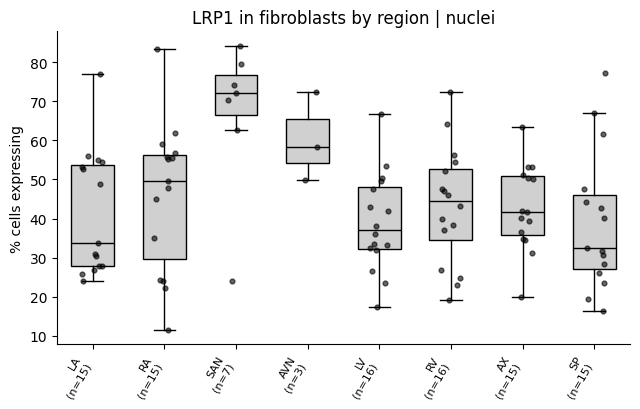

/tmp/ipykernel_386/3760262614.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  n = x.groupby(keys).size().rename('n_cells')
/tmp/ipykernel_386/3760262614.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pct = (x > 0).groupby(keys).mean().mul(100)
/tmp/ipykernel_386/3760262614.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean = x.groupby(keys).mean()


[심방 vs 심실 섬유모세포, 발현 세포 비율]


,gene,n_donors,atria_higher,atria_median,ventricle_median,p,p_adj
0,LRP1,16,10,46.6394,37.2618,0.4332,1.0000
1,ADAM10,16,11,21.8450,15.7767,0.1046,0.8367
2,ADAM12,16,12,3.7192,2.8645,0.1439,1.0000
3,ADAM17,16,13,26.5687,21.9385,0.0063,0.0566
4,MMP14,16,7,6.5252,6.8397,0.4637,1.0000
5,MMP15,16,9,0.1761,0.0738,0.2312,1.0000
6,MMP16,16,6,13.1298,12.1559,0.3484,1.0000
7,MMP17,16,10,1.3997,0.8269,0.1439,1.0000
8,BACE1,16,11,6.2001,5.0878,0.1439,1.0000


In [13]:
by_region = unit_table(['donor', 'region'], min_cells=MIN_STATE, mask=is_nuc)
by_region.round(4).to_csv(OUT / '03_fb_region_donor_level.csv', index=False)
region_order = [r for r in ['LA', 'RA', 'SAN', 'AVN', 'LV', 'RV', 'AX', 'SP'] if r in set(by_region['region'])]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
d = by_region[by_region['gene'] == 'LRP1']
boxes(ax, region_order, [d.loc[d['region'] == r, 'pct'].values for r in region_order], 'LRP1 in fibroblasts by region | nuclei')
plt.tight_layout()
plt.savefig(OUT / '03_fb_region_boxplot_LRP1.png', dpi=200, bbox_inches='tight')
plt.show()

by_chamber = unit_table(['donor', 'chamber'], min_cells=MIN_CELLS, mask=is_nuc)
rows = []
for gene in GENES:
    w = by_chamber[by_chamber['gene'] == gene].pivot(index='donor', columns='chamber', values='pct')
    if {'Atria', 'Ventricle'} <= set(w.columns):
        pair = w[['Atria', 'Ventricle']].dropna()
        if len(pair) >= 6:
            diff = pair['Atria'] - pair['Ventricle']
            rows.append(dict(gene=gene, n_donors=len(pair), atria_higher=int((diff > 0).sum()),
                             atria_median=pair['Atria'].median(), ventricle_median=pair['Ventricle'].median(),
                             p=wilcoxon(diff).pvalue if (diff != 0).any() else 1.0))
test_chamber = pd.DataFrame(rows)
test_chamber['p_adj'] = multipletests(test_chamber['p'], method='holm')[1]
test_chamber.round(4).to_csv(OUT / '03_test_atria_vs_ventricle.csv', index=False)
print('[심방 vs 심실 섬유모세포, 발현 세포 비율]')
test_chamber.round(4)

## 5. 분석 4: 어떤 sheddase가 우세한가

### 섬유모세포 안에서의 순위

핵 데이터에서 공여자별 발현 세포 비율의 중앙값 순으로 정렬합니다. 02번 결과(섬유모세포가 다른 세포 유형보다 높은지)와 나란히 보면, "많이 나오는 것"과 "섬유모세포에 특이적인 것"을 구분할 수 있습니다.

In [14]:
nuc_donor = by_donor[by_donor['cell_or_nuclei'] == 'Nuclei']
rank = (nuc_donor[nuc_donor['gene'].isin(SHEDDASES)].groupby('gene')['pct']
        .agg(median='median', q25=lambda v: v.quantile(.25), q75=lambda v: v.quantile(.75), n_donors='size')
        .sort_values('median', ascending=False))
rank['family'] = ['ADAM' if g.startswith('ADAM') else 'MT-MMP' if g.startswith('MMP') else 'BACE' for g in rank.index]
rank.round(2).to_csv(OUT / '03_sheddase_rank_in_fb.csv')
rank.round(2)

,median,q25,q75,n_donors,family
gene,,,,,
ADAM17,29.94,18.73,38.01,22,ADAM
ADAM10,21.11,11.52,35.64,22,ADAM
MMP16,13.49,8.07,17.98,22,MT-MMP
MMP14,9.36,5.51,16.42,22,MT-MMP
BACE1,7.27,3.96,9.60,22,BACE
ADAM12,6.42,2.53,14.89,22,ADAM
MMP17,1.35,0.57,1.94,22,MT-MMP
MMP15,0.18,0.07,0.38,22,MT-MMP


### 절단 방식별: ADAM 계열과 MT-MMP 계열

세포 하나에서 ADAM 계열(ADAM10, 12, 17) 중 하나라도 검출된 비율과, MT-MMP 계열(MMP14, 15, 16, 17) 중 하나라도 검출된 비율입니다(핵 데이터).

In [15]:
pos = X[is_nuc] > 0
fam = pd.DataFrame({
    'LRP1': pos['LRP1'],
    'any_ADAM': pos[[g for g in SHEDDASES if g.startswith('ADAM')]].any(axis=1),
    'any_MT-MMP': pos[[g for g in SHEDDASES if g.startswith('MMP')]].any(axis=1),
})
fam['LRP1+ADAM'] = fam['LRP1'] & fam['any_ADAM']
fam['LRP1+MT-MMP'] = fam['LRP1'] & fam['any_MT-MMP']
state_n = fb.obs.loc[is_nuc, 'cell_state'].values
family_table = pd.concat([fam.mean().mul(100).rename('All fibroblasts').to_frame().T,
                          fam.groupby(state_n).mean().mul(100)])
family_table.round(1).to_csv(OUT / '03_sheddase_family_by_state.csv')
family_table.round(1)

/tmp/ipykernel_386/2436925908.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fam.groupby(state_n).mean().mul(100)])


,LRP1,any_ADAM,any_MT-MMP,LRP1+ADAM,LRP1+MT-MMP
All fibroblasts,52.3,46.0,25.7,28.4,16.9
FB1,39.5,29.6,21.1,13.1,10.3
FB2,59.9,48.0,28.4,33.6,20.6
FB3,53.4,55.9,22.5,35.1,15.7
FB4_activated,54.5,57.1,27.1,34.4,18.1
FB5,62.7,42.9,31.0,30.6,22.2
FB6,58.1,53.9,34.6,36.6,24.2
unclassified,63.4,71.3,39.8,54.7,33.2


### LRP1과 같은 세포에서 함께 검출되는가

- **shed_in_LRP1pos / shed_in_LRP1neg**: LRP1이 검출된 세포와 검출되지 않은 세포에서 각각 그 sheddase가 검출된 비율(%)
- **ratio_depth_adj**: 관찰된 공동 검출 / 우연히 기대되는 공동 검출. 1이면 우연 수준, 1보다 크면 우연보다 자주 함께 검출됩니다.

RNA가 많이 잡힌 세포는 어떤 유전자든 함께 검출되기 쉬우므로, 단순 비교(ratio_naive)는 항상 1보다 크게 나오는 경향이 있습니다.
그래서 RNA 총량이 비슷한 세포끼리 묶어(10구간) 기대값을 계산한 **ratio_depth_adj**를 기준으로 봅니다.

In [16]:
obs_n = fb.obs[is_nuc]
depth_bin = pd.qcut(obs_n['total_counts'], 10, labels=False, duplicates='drop').values

def codetection(mask=None):
    m = np.ones(len(obs_n), bool) if mask is None else mask
    a = pos['LRP1'].values[m]
    bins = depth_bin[m]
    rows = []
    for g in SHEDDASES:
        b = pos[g].values[m]
        t = pd.DataFrame({'a': a, 'b': b, 'bin': bins}).groupby('bin').agg(n=('a', 'size'), pa=('a', 'mean'), pb=('b', 'mean'))
        expected_adj = (t['n'] * t['pa'] * t['pb']).sum()
        expected_naive = len(a) * a.mean() * b.mean()
        both = (a & b).sum()
        rows.append(dict(sheddase=g, n_cells=len(a), pct_LRP1=100 * a.mean(), pct_shed=100 * b.mean(),
                         pct_both=100 * both / len(a),
                         shed_in_LRP1pos=100 * b[a].mean() if a.any() else np.nan,
                         shed_in_LRP1neg=100 * b[~a].mean() if (~a).any() else np.nan,
                         ratio_naive=both / expected_naive if expected_naive > 0 else np.nan,
                         ratio_depth_adj=both / expected_adj if expected_adj >= 20 else np.nan))
    return pd.DataFrame(rows)

co_all = codetection()
co_all.round(3).to_csv(OUT / '03_codetection_all_fb.csv', index=False)
co_all.round(2)

,sheddase,n_cells,pct_LRP1,pct_shed,pct_both,shed_in_LRP1pos,shed_in_LRP1neg,ratio_naive,ratio_depth_adj
0,ADAM10,134892,52.28,23.83,16.29,31.16,15.79,1.31,1.02
1,ADAM12,134892,52.28,10.68,6.84,13.08,8.06,1.22,0.96
2,ADAM17,134892,52.28,28.03,17.85,34.14,21.35,1.22,0.99
3,MMP14,134892,52.28,11.31,8.01,15.32,6.92,1.35,1.10
4,MMP15,134892,52.28,0.30,0.24,0.47,0.12,1.54,1.08
5,MMP16,134892,52.28,15.86,10.20,19.51,11.87,1.23,1.00
6,MMP17,134892,52.28,1.35,0.97,1.85,0.79,1.38,1.04
7,BACE1,134892,52.28,7.08,4.98,9.52,4.41,1.34,1.04


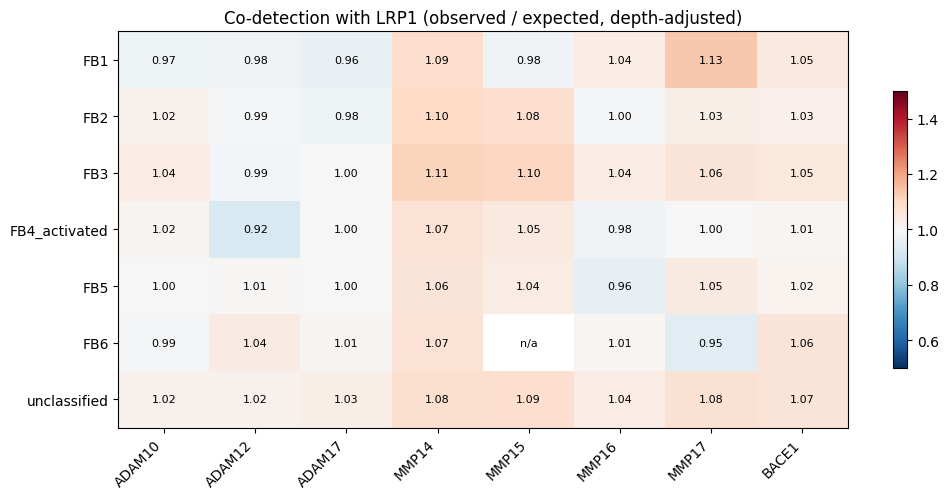

In [17]:
co_state = pd.concat([codetection((obs_n['cell_state'] == s).values).assign(cell_state=s) for s in STATES])
co_state.round(3).to_csv(OUT / '03_codetection_by_state.csv', index=False)
heat = co_state.pivot(index='cell_state', columns='sheddase', values='ratio_depth_adj')[SHEDDASES]

fig, ax = plt.subplots(figsize=(1.0 * len(SHEDDASES) + 2.5, 0.5 * len(heat) + 1.6))
vmax = max(1.5, np.nanmax(heat.values))
im = ax.imshow(heat.values, cmap='RdBu_r', norm=TwoSlopeNorm(vmin=min(0.5, np.nanmin(heat.values)), vcenter=1, vmax=vmax), aspect='auto')
ax.set_xticks(range(len(SHEDDASES)))
ax.set_xticklabels(SHEDDASES, rotation=45, ha='right')
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, 'n/a' if np.isnan(v) else f'{v:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('Co-detection with LRP1 (observed / expected, depth-adjusted)')
plt.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.savefig(OUT / '03_heatmap_codetection.png', dpi=200, bbox_inches='tight')
plt.show()

In [18]:
for f in sorted(OUT.glob('03_*')):
    print(f.name)

03_codetection_all_fb.csv
03_codetection_by_state.csv
03_dotplot_fb_state.png
03_dotplot_fb_state_markers.png
03_fb_LRP1_technical.csv
03_fb_LRP1_technical.png
03_fb_by_state.csv
03_fb_donor_level.csv
03_fb_donor_summary.csv
03_fb_genes_by_donor.png
03_fb_region_boxplot_LRP1.png
03_fb_region_donor_level.csv
03_fb_state_boxplot_LRP1.png
03_fb_state_boxplot_sheddases.png
03_fb_state_donor_level.csv
03_heatmap_codetection.png
03_overview_fb_states.csv
03_sheddase_family_by_state.csv
03_sheddase_rank_in_fb.csv
03_test_atria_vs_ventricle.csv
03_test_state_vs_rest.csv
03_test_state_vs_rest_summary.csv
